# Prédiction du désabonnement (churn) de clients télécoms

**Auteure :** Oumayma ZARAI — ENSIT

**Objectif :** prédire si un client va résilier son abonnement, à partir de ses caractéristiques (contrat, ancienneté, facturation, services).

**Données :** *Telco Customer Churn* (Kaggle), 7 043 clients, 21 colonnes.

**Méthode :** nettoyage → exploration → préparation → comparaison de 3 modèles → évaluation → interprétation.

## Étape 1 — Imports et chargement des données

Téléchargez le fichier `WA_Fn-UseC_-Telco-Customer-Churn.csv` sur Kaggle (*Telco Customer Churn*) et placez-le dans le même dossier que ce notebook.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, f1_score)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Étape 2 — Nettoyage

- `TotalCharges` est lu comme texte : certaines valeurs sont vides (clients tout nouveaux).
- `customerID` est un identifiant : il n'apporte aucune information prédictive.
- La cible `Churn` passe de Yes/No à 1/0.

In [2]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Valeurs manquantes :\n", df.isna().sum()[df.isna().sum() > 0])

# Les clients avec TotalCharges vide ont une ancienneté de 0 : on met 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print("\nTaux de churn :", round(df["Churn"].mean() * 100, 1), "%")

Valeurs manquantes :
 TotalCharges    11
dtype: int64

Taux de churn : 26.5 %


## Étape 3 — Exploration des données

On cherche les facteurs qui semblent liés au départ des clients.

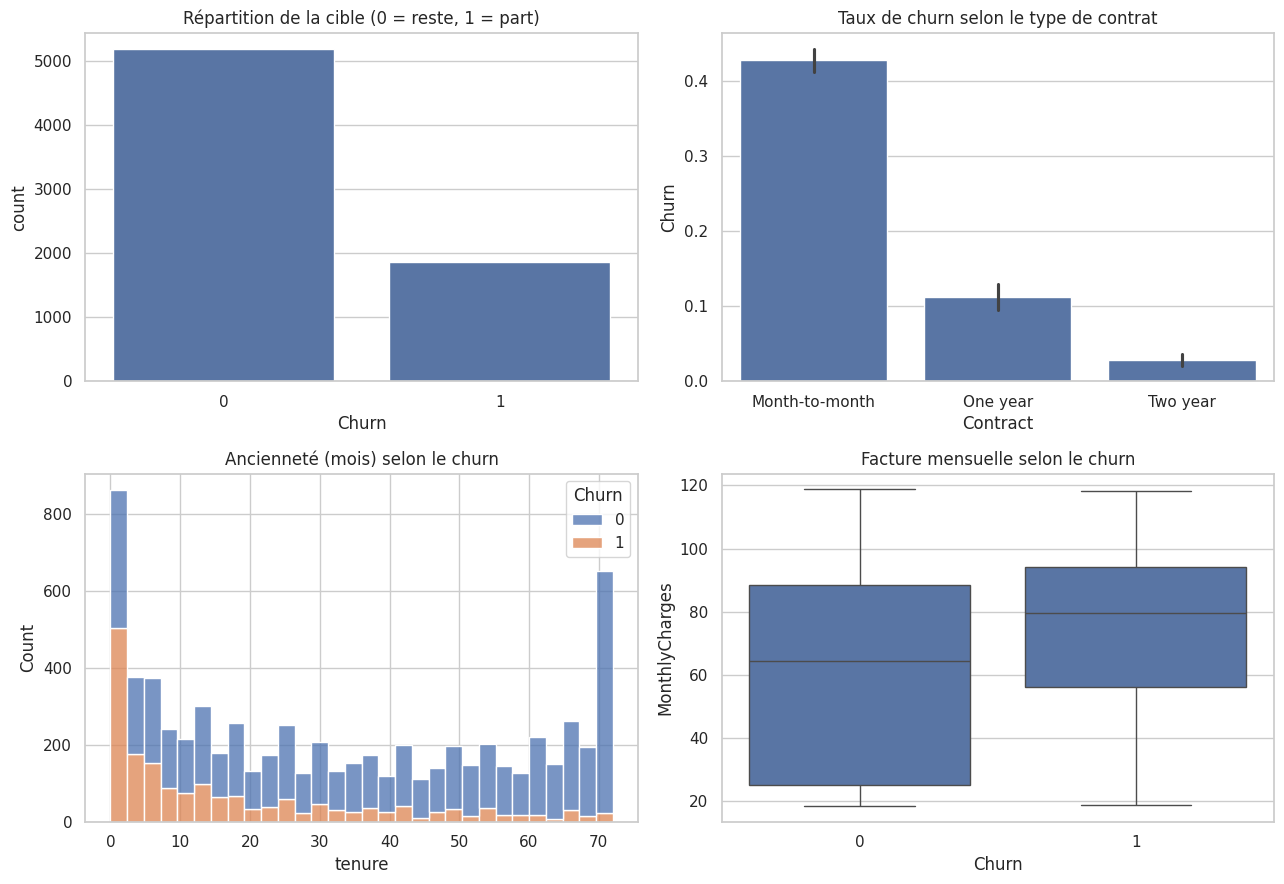

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Répartition de la cible (0 = reste, 1 = part)")

sns.barplot(data=df, x="Contract", y="Churn", ax=axes[0, 1])
axes[0, 1].set_title("Taux de churn selon le type de contrat")

sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack", ax=axes[1, 0])
axes[1, 0].set_title("Ancienneté (mois) selon le churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 1])
axes[1, 1].set_title("Facture mensuelle selon le churn")

plt.tight_layout(); plt.show()

 les clients à contrat mensuel, avec peu d'ancienneté et une facture mensuelle élevée partent davantage.

## Étape 4 — Préparation

- Séparation entraînement (80 %) / test (20 %), en conservant la proportion de churn (`stratify`).
- Variables numériques : normalisation.
- Variables catégorielles : encodage one-hot.
- Tout est regroupé dans un `Pipeline` pour éviter la fuite de données.

In [4]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
print("Numériques :", num_cols)
print("Catégorielles :", len(cat_cols), "colonnes")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

Numériques : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Catégorielles : 15 colonnes


## Étape 5 — Entraînement et comparaison de 3 modèles

Le jeu de données est déséquilibré (environ 27 % de churn). On utilise donc le **F1-score** et l'**AUC** plutôt que la seule précision. On compare par validation croisée (5 plis) sur l'entraînement.

In [5]:
models = {
    "Régression logistique": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

pipes, rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    f1_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1").mean()
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    pipes[name] = pipe
    rows.append({"Modèle": name, "F1 (CV)": round(f1_cv, 3), "AUC (CV)": round(auc_cv, 3)})

pd.DataFrame(rows).set_index("Modèle")

,F1 (CV),AUC (CV)
Modèle,,
Régression logistique,0.632,0.845
Random Forest,0.550,0.825
Gradient Boosting,0.586,0.847


## Étape 6 — Évaluation sur le jeu de test

On évalue les trois modèles sur des données jamais vues.

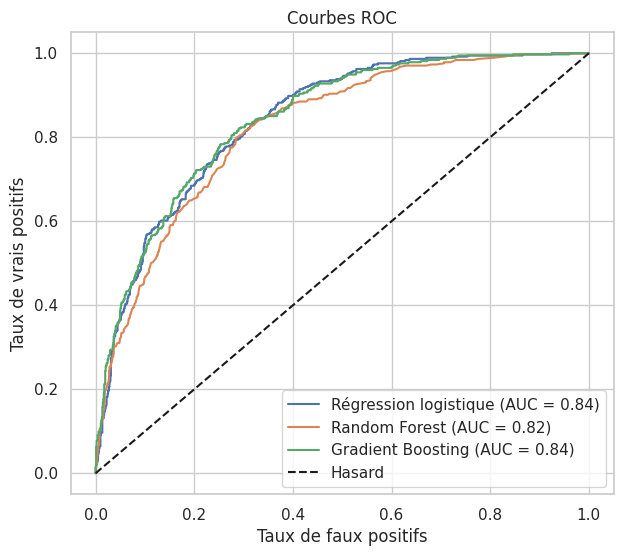

,F1 (test),AUC (test)
Modèle,,
Régression logistique,0.614,0.842
Random Forest,0.537,0.823
Gradient Boosting,0.581,0.843


In [6]:
results = []
plt.figure(figsize=(7, 6))
for name, pipe in pipes.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    results.append({"Modèle": name,
                    "F1 (test)": round(f1_score(y_test, pred), 3),
                    "AUC (test)": round(roc_auc_score(y_test, proba), 3)})
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.xlabel("Taux de faux positifs"); plt.ylabel("Taux de vrais positifs")
plt.title("Courbes ROC"); plt.legend(); plt.show()

pd.DataFrame(results).set_index("Modèle")

Meilleur modèle : Gradient Boosting 

              precision    recall  f1-score   support

       Reste       0.84      0.91      0.87      1035
        Part       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409



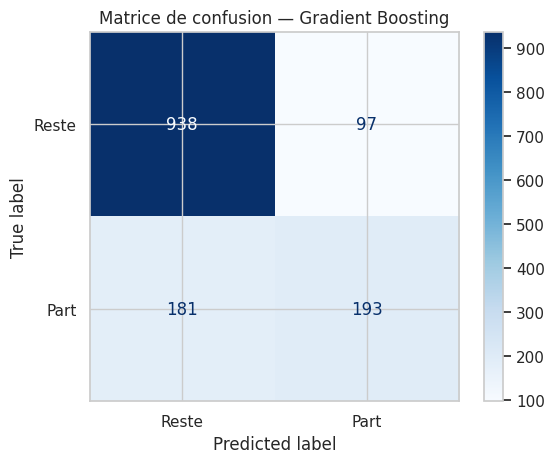

In [7]:
# Meilleur modèle selon l'AUC de test
best_name = max(results, key=lambda r: r["AUC (test)"])["Modèle"]
best = pipes[best_name]
pred = best.predict(X_test)
print("Meilleur modèle :", best_name, "\n")
print(classification_report(y_test, pred, target_names=["Reste", "Part"]))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Reste", "Part"]).plot(cmap="Blues")
plt.title(f"Matrice de confusion — {best_name}"); plt.show()

## Étape 7 — Interprétation : quels facteurs expliquent le départ ?

On regarde l'importance des variables du Random Forest.

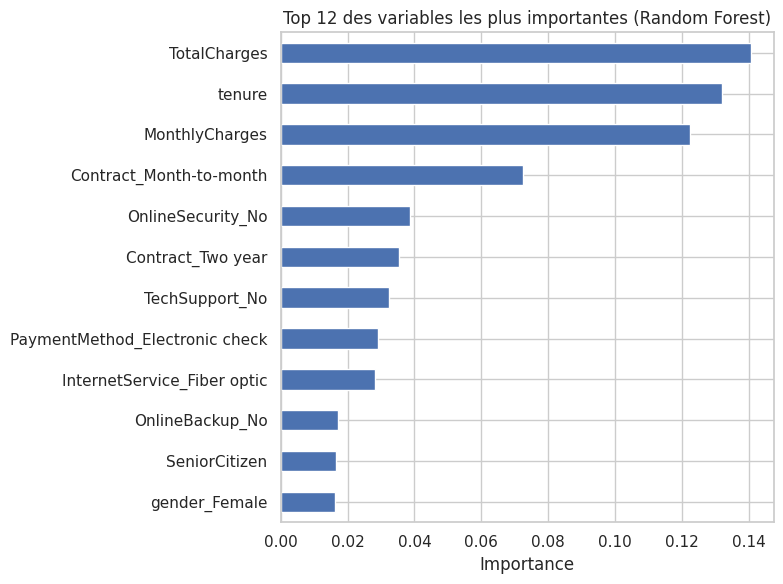

In [8]:
rf = pipes["Random Forest"]
feat_names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=feat_names)
imp.index = [n.replace("num__", "").replace("cat__", "") for n in imp.index]

imp.sort_values().tail(12).plot(kind="barh", figsize=(8, 6))
plt.title("Top 12 des variables les plus importantes (Random Forest)")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

## Conclusion

*(Complétez avec vos vrais chiffres affichés plus haut.)*

- Le meilleur modèle est **Gradient Boosting **, avec un AUC de ** 0.843 ** et un F1-score de **0.581 ** sur le jeu de test.
- Les facteurs les plus liés au départ sont **[totalcharges,tenure,Monthlycharges]**.
- **Limites :** jeu de données unique, pas d'optimisation poussée des hyperparamètres.
- **Pistes d'amélioration :** réglage des hyperparamètres (GridSearchCV), seuil de décision adapté au coût métier, essai de XGBoost, explication par SHAP.